SOCIAL NETWORK ADS DATASET

First 5 Records:
    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0

Dataset Shape:
(400, 5)

Dataset Columns:
Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB

Missing Values:
U

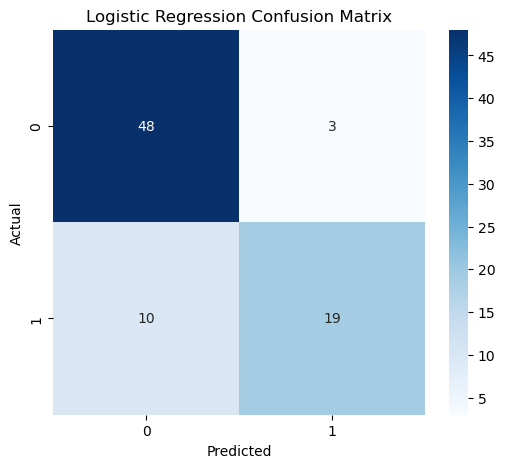

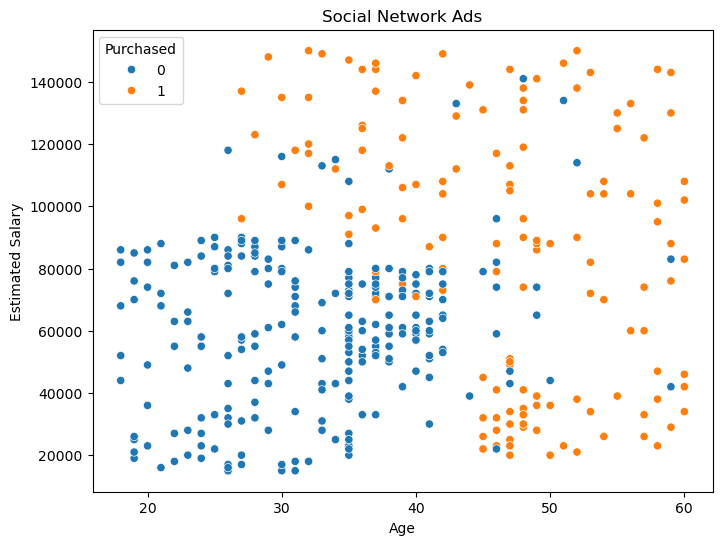


NEW USER PREDICTION
Age: 35
Estimated Salary: 80000
Logistic Regression Prediction: [0]
User is unlikely to purchase the product.

KNN Prediction: [0]
KNN: User is unlikely to purchase the product.

Decision Tree Prediction: [0]
Decision Tree: User is unlikely to purchase the product.

FINAL RESULT
                 Model  Accuracy
0  Logistic Regression    0.8375
1                  KNN    0.9000
2        Decision Tree    0.8250

Experiment completed successfully.


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [4]:
# EXPERIMENT NO. 4

# Step 1: Import Required Libraries


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)



# Step 2: Load Dataset


data = pd.read_csv("Social_Network_Ads.csv")

print("=" * 60)
print("SOCIAL NETWORK ADS DATASET")
print("=" * 60)

print("\nFirst 5 Records:")
print(data.head())



# Step 3: Explore Dataset


print("\nDataset Shape:")
print(data.shape)

print("\nDataset Columns:")
print(data.columns)

print("\nDataset Information:")
data.info()

print("\nMissing Values:")
print(data.isnull().sum())

print("\nStatistical Summary:")
print(data.describe())



# Step 4: Select Features and Target


# Input features
X = data[["Age", "EstimatedSalary"]]

# Target variable
y = data["Purchased"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())



# Step 5: Train-Test Split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 60)
print("TRAIN-TEST SPLIT")
print("=" * 60)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)



# Step 6: Feature Scaling


scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed.")



# Step 7: Logistic Regression


log_model = LogisticRegression()

# Train model
log_model.fit(X_train_scaled, y_train)

# Prediction
y_pred_log = log_model.predict(X_test_scaled)

# Accuracy
accuracy_log = accuracy_score(y_test, y_pred_log)

print("\n" + "=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)

print("Accuracy:", accuracy_log)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))



# Step 8: K-Nearest Neighbors (KNN)


knn_model = KNeighborsClassifier(n_neighbors=5)

# Train model
knn_model.fit(X_train_scaled, y_train)

# Prediction
y_pred_knn = knn_model.predict(X_test_scaled)

# Accuracy
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("\n" + "=" * 60)
print("K-NEAREST NEIGHBORS (KNN)")
print("=" * 60)

print("Accuracy:", accuracy_knn)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))



# Step 9: Decision Tree


tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train model
tree_model.fit(X_train, y_train)

# Prediction
y_pred_tree = tree_model.predict(X_test)

# Accuracy
accuracy_tree = accuracy_score(y_test, y_pred_tree)

print("\n" + "=" * 60)
print("DECISION TREE")
print("=" * 60)

print("Accuracy:", accuracy_tree)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))



# Step 10: Compare the Three Models


results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree"
    ],

    "Accuracy": [
        accuracy_log,
        accuracy_knn,
        accuracy_tree
    ]
})

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(results)



# Step 11: Precision, Recall and F1 Score


models = {
    "Logistic Regression": y_pred_log,
    "KNN": y_pred_knn,
    "Decision Tree": y_pred_tree
}

print("\n" + "=" * 60)
print("PRECISION, RECALL AND F1 SCORE")
print("=" * 60)

for name, prediction in models.items():

    print("\n", name)

    print(
        "Precision:",
        precision_score(y_test, prediction)
    )

    print(
        "Recall:",
        recall_score(y_test, prediction)
    )

    print(
        "F1 Score:",
        f1_score(y_test, prediction)
    )



# Step 12: Confusion Matrix


cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()



# Step 13: Visualization of Purchase Data


plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x="Age",
    y="EstimatedSalary",
    hue="Purchased"
)

plt.title("Social Network Ads")
plt.xlabel("Age")
plt.ylabel("Estimated Salary")

plt.show()



# Step 14: Predict a New User


# New user's Age = 35
# New user's Estimated Salary = 80000

new_user = [[35, 80000]]

# Scale new user data
new_user_scaled = scaler.transform(new_user)

# Logistic Regression Prediction
prediction_log = log_model.predict(new_user_scaled)

print("\n" + "=" * 60)
print("NEW USER PREDICTION")
print("=" * 60)

print("Age:", new_user[0][0])
print("Estimated Salary:", new_user[0][1])

print("Logistic Regression Prediction:", prediction_log)


if prediction_log[0] == 1:
    print("User is likely to purchase the product.")
else:
    print("User is unlikely to purchase the product.")



# Step 15: Predict Using KNN


prediction_knn = knn_model.predict(new_user_scaled)

print("\nKNN Prediction:", prediction_knn)

if prediction_knn[0] == 1:
    print("KNN: User is likely to purchase the product.")
else:
    print("KNN: User is unlikely to purchase the product.")



# Step 16: Predict Using Decision Tree


# Decision Tree does not require scaled input
prediction_tree = tree_model.predict(new_user)

print("\nDecision Tree Prediction:", prediction_tree)

if prediction_tree[0] == 1:
    print("Decision Tree: User is likely to purchase the product.")
else:
    print("Decision Tree: User is unlikely to purchase the product.")



# Step 17: Final Result


print("\n" + "=" * 60)
print("FINAL RESULT")
print("=" * 60)

print(results)

print("\nExperiment completed successfully.")